# Step 09: clustering
This notebook groups patients by their first 8 hours with K-Means, Ward and DBSCAN and checks whether the groups differ in sepsis rate.

In [1]:
import contextlib
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from tqdm import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
K_RANGE = range(2, 9)
SIL_N = 10_000
WARD_N = 5_000
DBSCAN_N = 20_000
DBSCAN_MIN_SAMPLES = 20
STAB_SEEDS = 5
SPLITS = ["train", "val", "test"]
COL = {"septic": "#d1495b", "control": "#2e86ab"}

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:.3f}".format
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

SUMMARY, SAVED = [], []
COUNT = {"pass": 0, "fail": 0}


def log(text=""):
    print(text)
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    ok = bool(ok)
    COUNT["pass" if ok else "fail"] += 1
    log(f"[{'PASS' if ok else 'FAIL'}] {label}" + (f" ({detail})" if detail != "" else ""))
    return ok


def expect(label, observed, expected, tol=0):
    return check(label, abs(observed - expected) <= tol, f"observed {observed}, expected {expected}")


@contextlib.contextmanager
def guarded(label):
    try:
        yield
    except Exception as e:
        check(label, False, f"{type(e).__name__}: {e}")


@contextlib.contextmanager
def timed(label):
    t0 = time.time()
    try:
        yield
    finally:
        log(f"{label}: {time.time() - t0:.1f} s")


@contextlib.contextmanager
def required(label):
    try:
        yield
    except Exception as e:
        raise RuntimeError(f"{label} failed ({type(e).__name__}: {e}); later sections depend on it, stopping") from e


def need(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(f"missing {missing}, run the earlier sections first")


def find_root():
    start = Path.cwd().resolve()
    for d in [start, *start.parents]:
        if (d / "dataset").is_dir():
            return d
    raise FileNotFoundError("no folder with a 'dataset' directory above " + str(start))


def save_fig(name):
    plt.tight_layout()
    path = FIG / name
    plt.savefig(path, dpi=150)
    SAVED.append(path)
    plt.show()
    plt.close()


def save_csv(df, name):
    path = TAB / name
    df.to_csv(path, index=False)
    SAVED.append(path)


def show(df):
    log(df.to_string(index=False))


ROOT = find_root()
PROC, TAB, FIG = ROOT / "data" / "processed", ROOT / "results" / "tables", ROOT / "results" / "figures"
for d in (PROC, TAB, FIG):
    d.mkdir(parents=True, exist_ok=True)
log(f"root: {ROOT}")

root: /Users/harnoorkaur/Downloads/Sepsis_ml


## Setup and input checks
Reads the patient table and compares it with the sizes known from the earlier steps.

In [2]:
with timed("section 1"):
    with required("reading patient_splits.csv"):
        splits = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": str, "hospital": str})
        splits["ever_septic"] = splits["ever_septic"].astype(int)
    with guarded("input checks"):
        check("features_flat.parquet exists", (PROC / "features_flat.parquet").exists())
        expect("unique patients", splits["patient_id"].nunique(), 40_336)
        expect("rows in patient_splits", len(splits), 40_336)
        for h, n in (("A", 20_336), ("B", 20_000)):
            expect(f"hospital {h} patients", int((splits["hospital"] == h).sum()), n)
        want = {"train": (28_235, 2_052, 298), "val": (6_050, 440, 65), "test": (6_051, 440, 63)}
        for s, (n, sep, first) in want.items():
            d = splits[splits["split"] == s]
            expect(f"{s} patients", len(d), n)
            expect(f"{s} septic patients", int(d["ever_septic"].sum()), sep)
            expect(f"{s} septic patients labelled in first row", int(((d["ever_septic"] == 1) & (d["first_positive_hour"] == 0)).sum()), first)
        expect("overall septic rate", round(splits["ever_septic"].mean(), 4), 0.0727, tol=0.0005)
        check("minimum n_rows is at least 8", splits["n_rows"].min() >= 8, f"min {splits['n_rows'].min()}")

[PASS] features_flat.parquet exists
[PASS] unique patients (observed 40336, expected 40336)
[PASS] rows in patient_splits (observed 40336, expected 40336)
[PASS] hospital A patients (observed 20336, expected 20336)
[PASS] hospital B patients (observed 20000, expected 20000)
[PASS] train patients (observed 28235, expected 28235)
[PASS] train septic patients (observed 2052, expected 2052)
[PASS] train septic patients labelled in first row (observed 298, expected 298)
[PASS] val patients (observed 6050, expected 6050)
[PASS] val septic patients (observed 440, expected 440)
[PASS] val septic patients labelled in first row (observed 65, expected 65)
[PASS] test patients (observed 6051, expected 6051)
[PASS] test septic patients (observed 440, expected 440)
[PASS] test septic patients labelled in first row (observed 63, expected 63)
[PASS] overall septic rate (observed 0.0727, expected 0.0727)
[PASS] minimum n_rows is at least 8 (min 8)
section 1: 0.0 s


## Patient feature table
One row per patient from hours 0 to 7, then median fill, log1p on the lab count and z-scores from the train patients.

In [3]:
VITALS = ["HR", "Resp", "Temp", "MAP", "SBP", "O2Sat"]
VCOLS = [f"{v}_mean8" for v in VITALS]
RAW = VCOLS + ["n_labs8", "Age", "unit_1", "unit_2"]
Z_COLS = [f"{c}_z" for c in RAW]
OUTCOME = ["ever_septic", "n_rows", "first_positive_hour", "SepsisLabel"]
KEYS = ["patient_id", "hospital"]


def prep(df):
    x = df[RAW].astype(float).fillna(MED)
    x["n_labs8"] = np.log1p(x["n_labs8"])
    return x


with timed("section 2"):
    need("splits")
    with required("building the patient feature table"):
        cols = KEYS + ["hour"] + VITALS + ["n_labs_so_far", "Age", "unit_1", "unit_2"]
        rows = pd.read_parquet(PROC / "features_flat.parquet", columns=cols, filters=[("hour", "<=", 7)])
        rows["patient_id"] = rows["patient_id"].astype(str)
        rows["hospital"] = rows["hospital"].astype(str)
        log(f"rows read: {len(rows):,}")
        feat = rows.groupby(KEYS, sort=False)[VITALS].mean()
        feat.columns = VCOLS
        feat["n_labs8"] = rows[rows["hour"] == 7].set_index(KEYS)["n_labs_so_far"]
        feat = feat.join(rows[rows["hour"] == 0].set_index(KEYS)[["Age", "unit_1", "unit_2"]]).reset_index()
        keep = KEYS + ["split", "ever_septic", "n_rows", "first_positive_hour"]
        pat = feat.merge(splits[keep], on=KEYS, how="left", validate="one_to_one")
        pat["split"] = pat["split"].astype(str)
        pat[RAW] = pat[RAW].astype(float)
        del rows, feat

        for c in VCOLS:
            log(f"patients with NaN in {c}: {int(pat[c].isna().sum())}")

        tr = (pat["split"] == "train").to_numpy()
        tr_idx = np.flatnonzero(tr)
        TRAIN_RATE = pat.loc[tr, "ever_septic"].mean()
        ALL_RATE = pat["ever_septic"].mean()
        MED = pat.loc[tr, RAW].median()
        Xp = prep(pat)
        MEAN, STD = Xp[tr].mean(), Xp[tr].std(ddof=0)
        pat[Z_COLS] = ((Xp - MEAN) / STD).to_numpy()
        Zall = pat[Z_COLS].to_numpy()
        Xtr = Zall[tr_idx]
        out = pat[KEYS + ["split"] + RAW + Z_COLS]
        out.to_parquet(PROC / "patient_cluster_features.parquet", index=False)
        SAVED.append(PROC / "patient_cluster_features.parquet")

    show(pat[RAW].describe().T.reset_index().rename(columns={"index": "feature"})[["feature", "mean", "std", "min", "50%", "max"]])
    with guarded("feature table checks"):
        expect("rows in feature table", len(out), 40_336)
        check("one row per patient", not out.duplicated(KEYS).any() and out["patient_id"].nunique() == 40_336)
        check("every patient has a split", pat["split"].isin(SPLITS).all())
        check("no NaN or inf in standardised columns", np.isfinite(out[Z_COLS].to_numpy()).all())
        expect("max abs train mean of z columns", float(np.abs(out.loc[tr, Z_COLS].mean()).max()), 0, tol=1e-3)
        expect("max abs deviation of train std from 1", float(np.abs(out.loc[tr, Z_COLS].std(ddof=0) - 1).max()), 0, tol=1e-3)
        bad = [c for c in RAW + Z_COLS if any(c.startswith(o) for o in OUTCOME)]
        check("no outcome column among the clustering inputs", not bad, str(bad))

rows read: 322,688
patients with NaN in HR_mean8: 47
patients with NaN in Resp_mean8: 575
patients with NaN in Temp_mean8: 1966
patients with NaN in MAP_mean8: 461
patients with NaN in SBP_mean8: 866
patients with NaN in O2Sat_mean8: 121
    feature    mean    std    min     50%     max
   HR_mean8  84.144 16.426 40.000  83.000 150.000
 Resp_mean8  18.056  4.117  3.000  17.643  43.000
 Temp_mean8  36.714  0.668 33.000  36.683  39.670
  MAP_mean8  82.841 14.062 40.500  80.688 158.000
  SBP_mean8 123.006 20.066 64.000 120.143 213.000
O2Sat_mean8  97.666  2.214 74.000  98.143 100.000
    n_labs8  15.256 13.841  0.000  13.000 120.000
        Age  61.643 16.483 14.000  63.110 100.000
     unit_1   0.304  0.460  0.000   0.000   1.000
     unit_2   0.309  0.462  0.000   0.000   1.000
[PASS] rows in feature table (observed 40336, expected 40336)
[PASS] one row per patient
[PASS] every patient has a split
[PASS] no NaN or inf in standardised columns
[PASS] max abs train mean of z columns (obser

## K-Means
K-Means is fitted for k from 2 to 8 on all train patients and k is picked by silhouette.

kmeans: 100%|██████████| 7/7 [00:04<00:00,  1.60it/s]

 k    inertia  silhouette  davies_bouldin
 2 244125.425       0.131           2.369
 3 217121.780       0.144           2.191
 4 199830.907       0.145           2.156
 5 187293.376       0.144           1.984
 6 178909.191       0.143           1.922
 7 171917.150       0.135           1.909
 8 166002.389       0.135           1.961
rule: k = 2 is reported but not eligible, selected k is the best silhouette among 3..8
k = 2 silhouette 0.131, selected k = 4 with silhouette 0.145


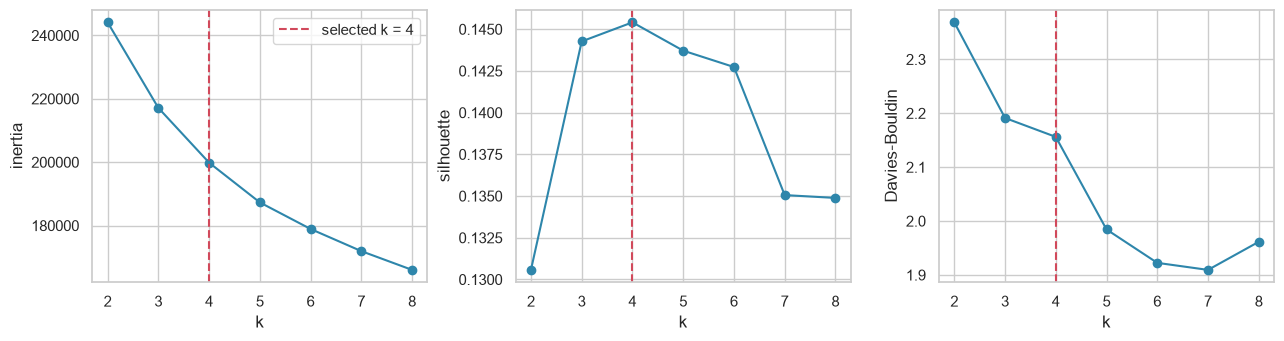

stability: 100%|██████████| 5/5 [00:00<00:00,  9.43it/s]

 seed  ari_vs_main
   43        0.994
   44        0.994
   45        0.995
   46        0.995
   47        0.994
stability ARI: mean 0.994, min 0.994
section 3: 5.1 s


In [4]:
with timed("section 3"):
    need("Xtr", "tr_idx", "Zall")
    with required("k-means selection"):
        sil_idx = np.random.default_rng(SEED).choice(len(Xtr), SIL_N, replace=False)
        recs, models = [], {}
        for k in tqdm(K_RANGE, desc="kmeans"):
            m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xtr)
            models[k] = m
            recs.append({"k": k, "inertia": m.inertia_,
                         "silhouette": silhouette_score(Xtr[sil_idx], m.labels_[sil_idx]),
                         "davies_bouldin": davies_bouldin_score(Xtr, m.labels_)})
        sel = pd.DataFrame(recs)
        save_csv(sel, "cluster_selection_k.csv")
        show(sel)
        elig = sel[sel["k"].between(3, 8)]
        K_SEL = int(elig.loc[elig["silhouette"].idxmax(), "k"])
        km = models[K_SEL]
        sil2 = float(sel.loc[sel["k"] == 2, "silhouette"].iloc[0])
        log(f"rule: k = 2 is reported but not eligible, selected k is the best silhouette among 3..8")
        log(f"k = 2 silhouette {sil2:.3f}, selected k = {K_SEL} with silhouette {float(sel.loc[sel['k'] == K_SEL, 'silhouette'].iloc[0]):.3f}")

        fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
        for a, col, name in zip(ax, ["inertia", "silhouette", "davies_bouldin"], ["inertia", "silhouette", "Davies-Bouldin"]):
            a.plot(sel["k"], sel[col], marker="o", color=COL["control"])
            a.axvline(K_SEL, color=COL["septic"], ls="--", label=f"selected k = {K_SEL}")
            a.set_xlabel("k")
            a.set_ylabel(name)
        ax[0].legend()
        save_fig("fig09_kmeans_selection.png")

        pat["kmeans"] = km.predict(Zall)

    with required("k-means stability"):
        seeds = [SEED + 1 + i for i in range(STAB_SEEDS)]
        stab = []
        for s in tqdm(seeds, desc="stability"):
            lab = KMeans(n_clusters=K_SEL, n_init=10, random_state=s).fit(Xtr).labels_
            stab.append({"seed": s, "ari_vs_main": adjusted_rand_score(km.labels_, lab)})
        stab = pd.DataFrame(stab)
        save_csv(stab, "cluster_stability.csv")
        show(stab)
        log(f"stability ARI: mean {stab['ari_vs_main'].mean():.3f}, min {stab['ari_vs_main'].min():.3f}")

## Profile of the K-Means clusters
Outcome columns are used here for the first time, only to describe the clusters.

 cluster  patients  share  septic_rate  lift  ci_low  ci_high  septic_first_row_share  median_n_rows  median_first_pos_hour  share_hospital_A
       0      8295  0.294        0.089 1.224   0.083    0.095                   0.104         39.000                 35.500             0.676
       1      6641  0.235        0.089 1.225   0.082    0.096                   0.201         39.000                 16.000             0.483
       2      7968  0.282        0.053 0.725   0.048    0.058                   0.140         38.000                 34.000             0.476
       3      5331  0.189        0.057 0.782   0.051    0.063                   0.142         38.000                 27.000             0.304
 cluster  HR_mean8  Resp_mean8  Temp_mean8  MAP_mean8  SBP_mean8  O2Sat_mean8  n_labs8    Age  unit_1  unit_2
       0    81.281      17.615      36.742     78.137    117.170       97.699   14.277 61.000   0.000   0.000
       1    87.065      19.364      36.649     77.269    114.165      

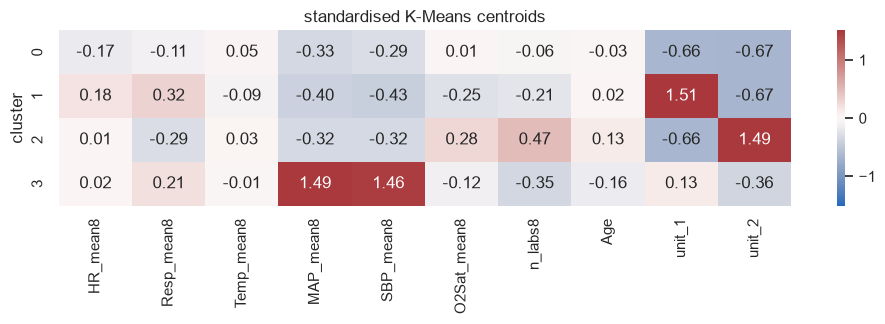

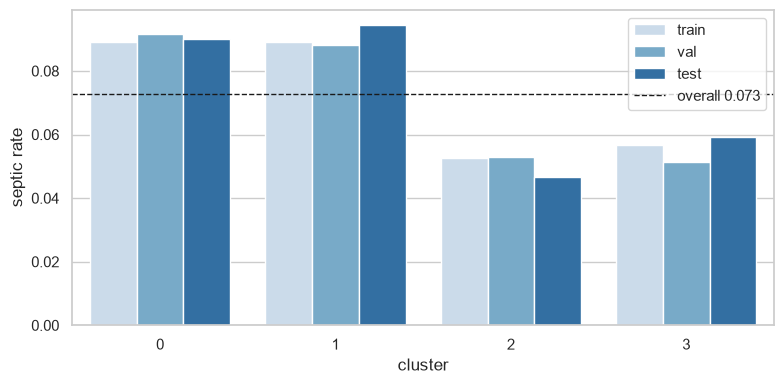

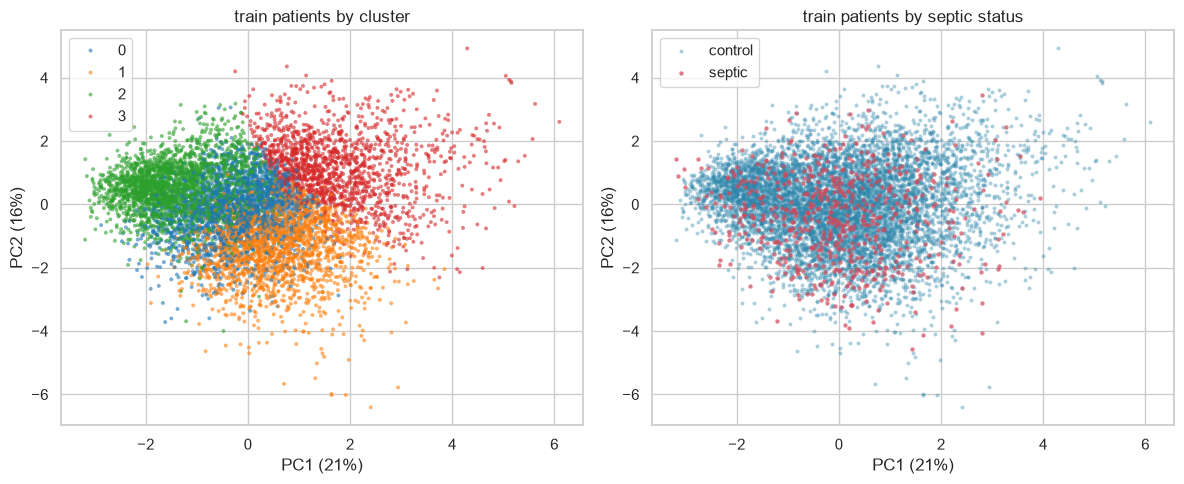

section 4: 0.6 s


In [5]:
def wilson(x, n, z=1.959964):
    if n == 0:
        return np.nan, np.nan
    p = x / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def profile(df, col, full=True):
    out_rows = []
    for c, d in df.groupby(col):
        n, s = len(d), int(d["ever_septic"].sum())
        lo, hi = wilson(s, n)
        r = {"cluster": int(c), "patients": n, "share": n / len(df), "septic_rate": s / n,
             "lift": s / n / TRAIN_RATE, "ci_low": lo, "ci_high": hi}
        if full:
            sep = d[d["ever_septic"] == 1]
            r["septic_first_row_share"] = (sep["first_positive_hour"] == 0).mean() if len(sep) else np.nan
            r["median_n_rows"] = d["n_rows"].median()
            r["median_first_pos_hour"] = sep["first_positive_hour"].median() if len(sep) else np.nan
            r["share_hospital_A"] = (d["hospital"] == "A").mean()
        r.update(d[RAW].mean().to_dict())
        out_rows.append(r)
    return pd.DataFrame(out_rows)


with timed("section 4"):
    need("km", "K_SEL", "pat")
    with required("k-means profile"):
        prof = profile(pat[tr], "kmeans")
        save_csv(prof, "cluster_profile_kmeans.csv")
        show(prof[["cluster", "patients", "share", "septic_rate", "lift", "ci_low", "ci_high",
                   "septic_first_row_share", "median_n_rows", "median_first_pos_hour", "share_hospital_A"]])
        show(prof[["cluster"] + RAW])

        by = (pat.groupby(["split", "kmeans"])["ever_septic"].agg(patients="size", septic="sum").reset_index()
              .rename(columns={"kmeans": "cluster"}))
        by["septic_rate"] = by["septic"] / by["patients"]
        by["split"] = pd.Categorical(by["split"], SPLITS, ordered=True)
        by = by.sort_values(["split", "cluster"]).reset_index(drop=True)
        by["split"] = by["split"].astype(str)
        save_csv(by, "cluster_septic_rate_by_split.csv")
        show(by)

    with guarded("chi-square tests and highest-risk clusters"):
        for s in SPLITS:
            d = pat[pat["split"] == s]
            chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(d["kmeans"], d["ever_septic"]))
            log(f"{s}: chi2 {chi2:.1f}, dof {dof}, p {p:.3g}")
        for s in SPLITS:
            sub = by[by["split"] == s]
            top = sub.loc[sub["septic_rate"].idxmax()]
            rate = sub["septic"].sum() / sub["patients"].sum()
            log(f"{s}: highest-risk cluster {int(top['cluster'])}, septic rate {top['septic_rate']:.3f}, "
                f"lift {top['septic_rate'] / rate:.2f} (vs split rate {rate:.3f}), share of split septic patients {top['septic'] / sub['septic'].sum():.3f}")

    with required("cluster figures"):
        cent = pd.DataFrame(km.cluster_centers_, columns=RAW)
        cent.index.name = "cluster"
        vmax = float(np.abs(cent.to_numpy()).max())
        fig, ax = plt.subplots(figsize=(10, 1.2 + 0.55 * K_SEL))
        sns.heatmap(cent, center=0, cmap="vlag", vmin=-vmax, vmax=vmax, annot=True, fmt=".2f", ax=ax)
        ax.set_title("standardised K-Means centroids")
        save_fig("fig09_cluster_centroids.png")

        fig, ax = plt.subplots(figsize=(8, 4))
        sns.barplot(data=by, x="cluster", y="septic_rate", hue="split", hue_order=SPLITS, palette="Blues", ax=ax)
        ax.axhline(ALL_RATE, color="k", ls="--", lw=1, label=f"overall {ALL_RATE:.3f}")
        ax.set_ylabel("septic rate")
        ax.legend()
        save_fig("fig09_cluster_septic_rate.png")

        pca = PCA(n_components=2, random_state=SEED).fit(Xtr)
        pidx = np.sort(np.random.default_rng(SEED + 3).choice(tr_idx, 8_000, replace=False))
        P = pca.transform(Zall[pidx])
        sub = pat.iloc[pidx]
        ev = pca.explained_variance_ratio_
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))
        sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=sub["kmeans"].astype(str).to_numpy(),
                        hue_order=[str(c) for c in range(K_SEL)], palette=sns.color_palette("tab10", K_SEL),
                        s=8, alpha=0.6, linewidth=0, ax=ax[0])
        ax[0].set_title("train patients by cluster")
        sep = sub["ever_septic"].to_numpy() == 1
        ax[1].scatter(P[~sep, 0], P[~sep, 1], s=8, alpha=0.4, color=COL["control"], linewidth=0, label="control")
        ax[1].scatter(P[sep, 0], P[sep, 1], s=10, alpha=0.7, color=COL["septic"], linewidth=0, label="septic")
        ax[1].set_title("train patients by septic status")
        ax[1].legend()
        for a in ax:
            a.set_xlabel(f"PC1 ({ev[0]:.0%})")
            a.set_ylabel(f"PC2 ({ev[1]:.0%})")
        save_fig("fig09_cluster_scatter.png")

## Ward hierarchical clustering
Ward linkage on a random sample of train patients, cut into the same number of clusters as K-Means.

ward: silhouette 0.120, Davies-Bouldin 2.321
k-means on the same patients: silhouette 0.145, Davies-Bouldin 2.152
adjusted Rand index ward vs k-means: 0.698
 cluster  patients  septic_rate  lift  HR_mean8  Resp_mean8  Temp_mean8  MAP_mean8  SBP_mean8  O2Sat_mean8  n_labs8    Age  unit_1  unit_2
       1      1409        0.049 0.674    83.698      16.941      36.731     78.762    117.385       98.244   21.870 64.575   0.000   0.999
       2      1387        0.105 1.438    87.568      19.837      36.659     79.040    116.765       97.243   11.828 61.726   0.902   0.003
       3       829        0.066 0.913    85.746      18.489      36.784    101.407    149.329       97.339   13.829 56.278   0.318   0.153
       4      1375        0.081 1.111    80.216      17.174      36.712     79.789    119.058       97.820   12.359 60.431   0.000   0.011


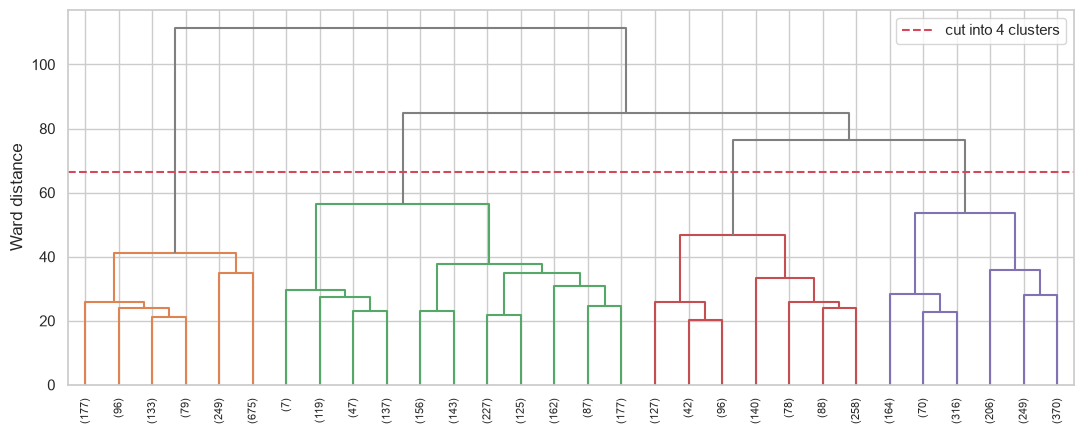

section 5: 0.7 s


In [6]:
with timed("section 5"):
    need("K_SEL", "km", "Zall", "tr_idx")
    with required("ward clustering"):
        ward_idx = np.sort(np.random.default_rng(SEED + 1).choice(tr_idx, WARD_N, replace=False))
        Xw = Zall[ward_idx]
        Zl = linkage(Xw, method="ward")
        ward_lab = fcluster(Zl, K_SEL, criterion="maxclust")
        km_w = pat["kmeans"].to_numpy()[ward_idx]
        ward_sil, ward_db = silhouette_score(Xw, ward_lab), davies_bouldin_score(Xw, ward_lab)
        km_sil_w, km_db_w = silhouette_score(Xw, km_w), davies_bouldin_score(Xw, km_w)
        ari_wk = adjusted_rand_score(km_w, ward_lab)
        log(f"ward: silhouette {ward_sil:.3f}, Davies-Bouldin {ward_db:.3f}")
        log(f"k-means on the same patients: silhouette {km_sil_w:.3f}, Davies-Bouldin {km_db_w:.3f}")
        log(f"adjusted Rand index ward vs k-means: {ari_wk:.3f}")
        pat["ward"] = np.nan
        pat.loc[ward_idx, "ward"] = ward_lab
        dfw = pat.iloc[ward_idx].copy()
        dfw["ward"] = ward_lab
        wprof = profile(dfw, "ward", full=False)
        save_csv(wprof, "cluster_ward_profile.csv")
        show(wprof[["cluster", "patients", "septic_rate", "lift"] + RAW])

        cut = (Zl[-K_SEL, 2] + Zl[-(K_SEL - 1), 2]) / 2
        fig, ax = plt.subplots(figsize=(11, 4.5))
        dendrogram(Zl, truncate_mode="lastp", p=30, show_leaf_counts=True, color_threshold=cut,
                   above_threshold_color="grey", leaf_rotation=90, leaf_font_size=8, ax=ax)
        ax.axhline(cut, color=COL["septic"], ls="--", label=f"cut into {K_SEL} clusters")
        ax.set_ylabel("Ward distance")
        ax.legend()
        save_fig("fig09_ward_dendrogram.png")

## DBSCAN
Eps comes from the knee of the k-distance curve, and the same distance rule flags unusual patients in every split.

eps 2.162 at quantile 0.938 of the sorted k-distance curve


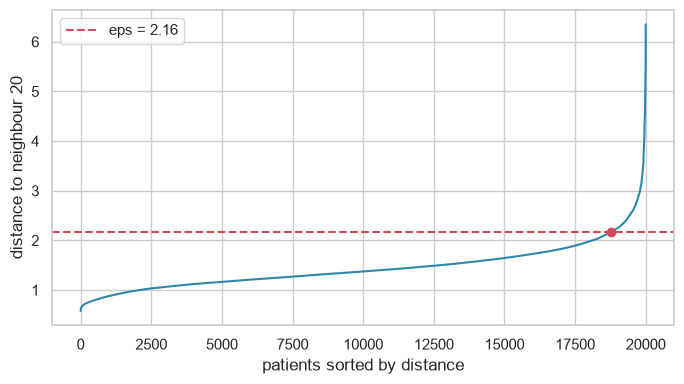

dbscan: 3 clusters, noise share 0.015
septic rate noise 0.178, non-noise 0.072
dbscan silhouette 0.154 on 10,000 non-noise patients
core samples: 18,767
split  patients  flagged  flagged_share  septic_rate_flagged  septic_rate_not_flagged
train     28235      406          0.014                0.172                    0.071
  val      6050      101          0.017                0.188                    0.071
 test      6051      108          0.018                0.185                    0.071
      group  patients  HR_mean8  Resp_mean8  Temp_mean8  MAP_mean8  SBP_mean8  O2Sat_mean8  n_labs8    Age  unit_1  unit_2
    flagged       406    99.062      24.292      36.437     85.212    122.041       92.526   18.889 58.433   0.458   0.241
not_flagged     27829    83.832      17.963      36.715     82.851    123.037       97.759   15.180 61.590   0.300   0.311
section 6: 3.0 s


In [7]:
with timed("section 6"):
    need("Zall", "tr_idx", "pat")
    with required("dbscan"):
        dbs_idx = np.sort(np.random.default_rng(SEED + 2).choice(tr_idx, DBSCAN_N, replace=False))
        Xd = Zall[dbs_idx]
        # the point itself is its first neighbour, as in dbscan's min_samples
        dist, _ = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(Xd).kneighbors(Xd)
        kd = np.sort(dist[:, -1])
        xs = np.linspace(0, 1, len(kd))
        ys = (kd - kd[0]) / (kd[-1] - kd[0])
        knee = int(np.argmax(np.abs(ys - xs)))
        EPS = float(kd[knee])
        log(f"eps {EPS:.3f} at quantile {xs[knee]:.3f} of the sorted k-distance curve")

        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(np.arange(len(kd)), kd, color=COL["control"])
        ax.axhline(EPS, color=COL["septic"], ls="--", label=f"eps = {EPS:.2f}")
        ax.scatter([knee], [EPS], color=COL["septic"], zorder=3)
        ax.set_xlabel("patients sorted by distance")
        ax.set_ylabel(f"distance to neighbour {DBSCAN_MIN_SAMPLES}")
        ax.legend()
        save_fig("fig09_dbscan_kdistance.png")

        db = DBSCAN(eps=EPS, min_samples=DBSCAN_MIN_SAMPLES, n_jobs=-1).fit(Xd)
        db_lab = db.labels_
        noise = db_lab == -1
        n_db = len(set(db_lab) - {-1})
        noise_share = noise.mean()
        sep_d = pat["ever_septic"].to_numpy()[dbs_idx]
        log(f"dbscan: {n_db} clusters, noise share {noise_share:.3f}")
        log(f"septic rate noise {sep_d[noise].mean() if noise.any() else np.nan:.3f}, "
            f"non-noise {sep_d[~noise].mean() if (~noise).any() else np.nan:.3f}")
        db_sil = db_db = ari_dk = np.nan
        if n_db >= 2:
            nn_pos = np.flatnonzero(~noise)
            sub_pos = np.sort(np.random.default_rng(SEED).choice(nn_pos, min(10_000, len(nn_pos)), replace=False))
            db_sil = silhouette_score(Xd[sub_pos], db_lab[sub_pos])
            db_db = davies_bouldin_score(Xd[~noise], db_lab[~noise])
            ari_dk = adjusted_rand_score(pat["kmeans"].to_numpy()[dbs_idx][~noise], db_lab[~noise])
            log(f"dbscan silhouette {db_sil:.3f} on {len(sub_pos):,} non-noise patients")
        else:
            log("fewer than 2 dbscan clusters, silhouette not defined")

        core = Xd[db.core_sample_indices_]
        if len(core) == 0:
            raise ValueError("no core samples, eps too small")
        d_core = NearestNeighbors(n_neighbors=1).fit(core).kneighbors(Zall)[0][:, 0]
        flag = d_core > EPS
        flag[dbs_idx[db.core_sample_indices_]] = False
        pat["dbscan_flag"] = flag
        log(f"core samples: {len(core):,}")

        recs = []
        for s in SPLITS:
            d = pat[pat["split"] == s]
            f = d["dbscan_flag"]
            recs.append({"split": s, "patients": len(d), "flagged": int(f.sum()), "flagged_share": f.mean(),
                         "septic_rate_flagged": d.loc[f, "ever_septic"].mean() if f.any() else np.nan,
                         "septic_rate_not_flagged": d.loc[~f, "ever_septic"].mean() if (~f).any() else np.nan})
        dsum = pd.DataFrame(recs)
        save_csv(dsum, "cluster_dbscan_summary.csv")
        show(dsum)

        trd = pat[tr]
        recs = []
        for name, m in (("flagged", trd["dbscan_flag"]), ("not_flagged", ~trd["dbscan_flag"])):
            recs.append({"group": name, "patients": int(m.sum()), **trd.loc[m, RAW].mean().to_dict()})
        dprof = pd.DataFrame(recs)
        save_csv(dprof, "cluster_dbscan_profile.csv")
        show(dprof)

## Method comparison and saved assignments
Compares the three methods, saves the assignments and the fitted objects, and checks the results.

In [8]:
with timed("section 7"):
    need("km", "K_SEL", "ward_lab", "EPS", "core", "dsum")
    with required("method comparison and saved files"):
        km_row = sel[sel["k"] == K_SEL].iloc[0]
        comp = pd.DataFrame([
            {"method": "kmeans", "patients_used": len(Xtr), "n_clusters": K_SEL, "silhouette": km_row["silhouette"],
             "davies_bouldin": km_row["davies_bouldin"], "noise_share": np.nan, "ari_vs_kmeans": np.nan},
            {"method": "ward", "patients_used": WARD_N, "n_clusters": len(np.unique(ward_lab)), "silhouette": ward_sil,
             "davies_bouldin": ward_db, "noise_share": np.nan, "ari_vs_kmeans": ari_wk},
            {"method": "dbscan", "patients_used": DBSCAN_N, "n_clusters": n_db, "silhouette": db_sil,
             "davies_bouldin": db_db, "noise_share": noise_share, "ari_vs_kmeans": ari_dk},
        ])
        save_csv(comp, "cluster_method_comparison.csv")
        show(comp)
        log("silhouette is on SIL_N train patients for kmeans, on the sample for ward and on up to 10,000 non-noise patients for dbscan")

        assign = pd.DataFrame({"patient_id": pat["patient_id"], "split": pat["split"],
                               "kmeans_cluster": pat["kmeans"].astype(int), "ward_cluster": pat["ward"],
                               "dbscan_flag": pat["dbscan_flag"].astype(bool)})
        assign.to_parquet(PROC / "cluster_assignments.parquet", index=False)
        SAVED.append(PROC / "cluster_assignments.parquet")
        joblib.dump({"features": RAW, "medians": MED, "means": MEAN, "stds": STD, "kmeans": km, "k": K_SEL,
                     "eps": EPS, "min_samples": DBSCAN_MIN_SAMPLES, "dbscan_core_samples": core},
                    PROC / "cluster_params.joblib")
        SAVED.append(PROC / "cluster_params.joblib")

    with guarded("final checks"):
        check("every patient has a k-means cluster", assign["kmeans_cluster"].notna().all() and len(assign) == 40_336)
        sizes = assign["kmeans_cluster"].value_counts()
        expect("k-means cluster sizes sum", int(sizes.sum()), 40_336)
        check("k-means silhouette and Davies-Bouldin finite", np.isfinite([km_row["silhouette"], km_row["davies_bouldin"]]).all())
        check("ward silhouette and Davies-Bouldin finite", np.isfinite([ward_sil, ward_db]).all())
        check("selected k between 3 and 8", 3 <= K_SEL <= 8, f"k {K_SEL}")
        expect("ward cut clusters", len(np.unique(ward_lab)), K_SEL)
        for s in SPLITS:
            m = (assign["split"] == s).to_numpy()
            fl, nf = int(assign.loc[m, "dbscan_flag"].sum()), int((~assign.loc[m, "dbscan_flag"]).sum())
            expect(f"dbscan flagged + not flagged in {s}", fl + nf, int((splits["split"] == s).sum()))
        expect("dbscan summary patients", int(dsum["patients"].sum()), 40_336)

method  patients_used  n_clusters  silhouette  davies_bouldin  noise_share  ari_vs_kmeans
kmeans          28235           4       0.145           2.156          NaN            NaN
  ward           5000           4       0.120           2.321          NaN          0.698
dbscan          20000           3       0.154           2.344        0.015          0.705
silhouette is on SIL_N train patients for kmeans, on the sample for ward and on up to 10,000 non-noise patients for dbscan
[PASS] every patient has a k-means cluster
[PASS] k-means cluster sizes sum (observed 40336, expected 40336)
[PASS] k-means silhouette and Davies-Bouldin finite
[PASS] ward silhouette and Davies-Bouldin finite
[PASS] selected k between 3 and 8 (k 4)
[PASS] ward cut clusters (observed 4, expected 4)
[PASS] dbscan flagged + not flagged in train (observed 28235, expected 28235)
[PASS] dbscan flagged + not flagged in val (observed 6050, expected 6050)
[PASS] dbscan flagged + not flagged in test (observed 6051, expec

## Output files
Lists every saved file with its size and writes the log.

In [9]:
with timed("section 8"):
    names = [PROC / "patient_cluster_features.parquet", PROC / "cluster_assignments.parquet", PROC / "cluster_params.joblib"]
    names += [TAB / n for n in ["cluster_selection_k.csv", "cluster_stability.csv", "cluster_profile_kmeans.csv",
                                "cluster_septic_rate_by_split.csv", "cluster_ward_profile.csv", "cluster_dbscan_summary.csv",
                                "cluster_dbscan_profile.csv", "cluster_method_comparison.csv"]]
    names += [FIG / n for n in ["fig09_kmeans_selection.png", "fig09_cluster_centroids.png", "fig09_cluster_septic_rate.png",
                                "fig09_cluster_scatter.png", "fig09_ward_dendrogram.png", "fig09_dbscan_kdistance.png"]]
    for p in names:
        ok = p.exists()
        check(f"saved {p.relative_to(ROOT)}", ok, f"{p.stat().st_size / 1e6:.2f} MB" if ok else "MISSING")
    log(f"checks: {COUNT['pass']} passed, {COUNT['fail']} failed")
    out_path = ROOT / "results" / "step09_summary.txt"
    out_path.write_text("\n".join(SUMMARY) + "\n", encoding="utf-8")
    print(out_path)

[PASS] saved data/processed/patient_cluster_features.parquet (1.60 MB)
[PASS] saved data/processed/cluster_assignments.parquet (0.30 MB)
[PASS] saved data/processed/cluster_params.joblib (1.62 MB)
[PASS] saved results/tables/cluster_selection_k.csv (0.00 MB)
[PASS] saved results/tables/cluster_stability.csv (0.00 MB)
[PASS] saved results/tables/cluster_profile_kmeans.csv (0.00 MB)
[PASS] saved results/tables/cluster_septic_rate_by_split.csv (0.00 MB)
[PASS] saved results/tables/cluster_ward_profile.csv (0.00 MB)
[PASS] saved results/tables/cluster_dbscan_summary.csv (0.00 MB)
[PASS] saved results/tables/cluster_dbscan_profile.csv (0.00 MB)
[PASS] saved results/tables/cluster_method_comparison.csv (0.00 MB)
[PASS] saved results/figures/fig09_kmeans_selection.png (0.08 MB)
[PASS] saved results/figures/fig09_cluster_centroids.png (0.08 MB)
[PASS] saved results/figures/fig09_cluster_septic_rate.png (0.03 MB)
[PASS] saved results/figures/fig09_cluster_scatter.png (0.51 MB)
[PASS] saved resu